Libraries imported successfully!

Dataset loaded successfully!

Original Dataset:


,label,sms,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN



Preprocessing completed!

Dataset shape: (5169, 2)

Class distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

Training samples: 4135
Testing samples: 1034

TF-IDF vectorization completed!
Training matrix shape: (4135, 5000)
Testing matrix shape: (1034, 5000)

Naive Bayes model trained successfully!

Predictions completed!

       MODEL ACCURACY
Accuracy: 97.00%

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       0.99      0.77      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.88      0.93      1034
weighted avg       0.97      0.97      0.97      1034



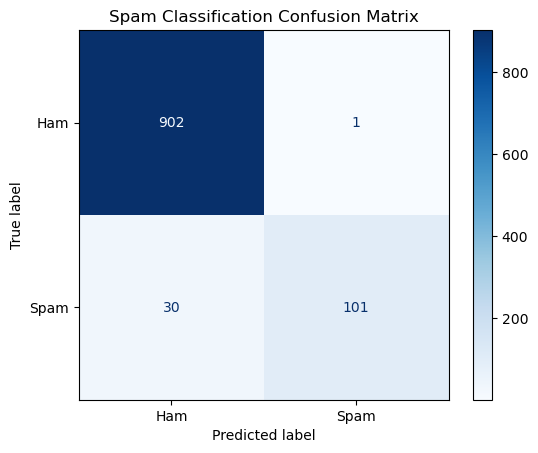


     CUSTOM MESSAGE TEST
Prediction: SPAM
Message: Congratulations! You have won a free prize. Call now!
------------------------------------------------------------
Prediction: HAM
Message: Hi, are we meeting tomorrow?
------------------------------------------------------------
Prediction: SPAM
Message: URGENT! You have won a cash reward. Click the link.
------------------------------------------------------------
Prediction: HAM
Message: Please send me the notes from today's class.
------------------------------------------------------------


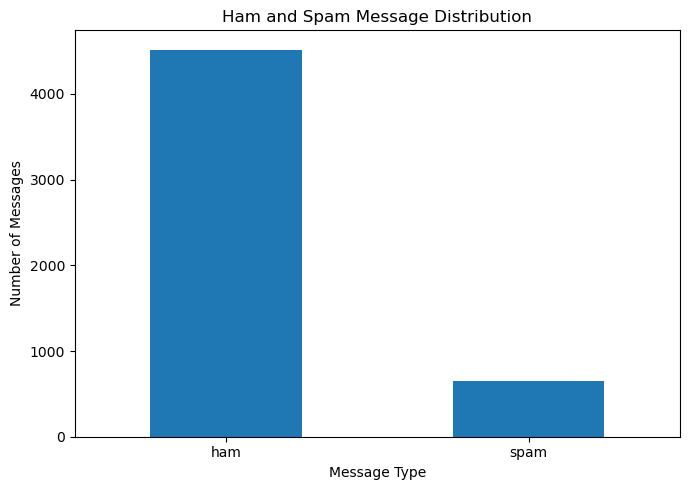


              RESULT
Spam filtering completed successfully!
Model Accuracy: 97.00%

Conclusion:
TF-IDF converted messages into numerical features.
Multinomial Naive Bayes classified messages.
The model predicts whether a message is HAM or SPAM.

PRACTICAL 4 COMPLETED!


In [13]:

# ============================================================
# PRACTICAL 4: SPAM FILTERING USING TEXT CLASSIFICATION
# Dataset: Uploaded Kaggle SMS Spam Collection (spam.csv)
# Algorithm: TF-IDF + Multinomial Naive Bayes
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


# 2. LOAD DATASET

df = pd.read_csv("spam.csv", encoding="latin-1")

print("\nDataset loaded successfully!")

print("\nOriginal Dataset:")
display(df.head())


# 3. DATA PREPROCESSING

# Your CSV contains label and sms columns.
# Ignore the extra Unnamed columns.

df = df[["label", "sms"]].copy()

# Rename columns
df.columns = ["label", "message"]

# Remove missing values
df.dropna(inplace=True)

# Remove duplicate messages
df.drop_duplicates(inplace=True)

# Normalize text and labels
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str)

# Keep only ham and spam
df = df[df["label"].isin(["ham", "spam"])].copy()

print("\nPreprocessing completed!")

print("\nDataset shape:", df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())


# 4. CONVERT LABELS INTO NUMBERS

# ham = 0
# spam = 1

df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

X = df["message"]
y = df["label_num"]


# 5. SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# 6. APPLY TF-IDF VECTORIZATION

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF vectorization completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)


# 7. TRAIN NAIVE BAYES CLASSIFIER

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("\nNaive Bayes model trained successfully!")


# 8. MAKE PREDICTIONS

y_pred = model.predict(X_test_tfidf)

print("\nPredictions completed!")


# 9. CALCULATE ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("\n==============================")
print("       MODEL ACCURACY")
print("==============================")

print(f"Accuracy: {accuracy * 100:.2f}%")


# 10. CLASSIFICATION REPORT

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


# 11. CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Spam Classification Confusion Matrix")

plt.show()


# 12. TEST CUSTOM MESSAGES

messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hi, are we meeting tomorrow?",
    "URGENT! You have won a cash reward. Click the link.",
    "Please send me the notes from today's class."
]

message_tfidf = tfidf.transform(messages)

predictions = model.predict(message_tfidf)

print("\n==============================")
print("     CUSTOM MESSAGE TEST")
print("==============================")

for message, prediction in zip(messages, predictions):

    if prediction == 1:
        print("Prediction: SPAM")
    else:
        print("Prediction: HAM")

    print("Message:", message)
    print("-" * 60)


# 13. VISUALIZE HAM AND SPAM DISTRIBUTION

class_counts = df["label"].value_counts()

plt.figure(figsize=(7, 5))

class_counts.plot(kind="bar")

plt.title("Ham and Spam Message Distribution")

plt.xlabel("Message Type")

plt.ylabel("Number of Messages")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()


# 14. FINAL RESULT

print("\n====================================")
print("              RESULT")
print("====================================")

print("Spam filtering completed successfully!")

print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nConclusion:")
print("TF-IDF converted messages into numerical features.")
print("Multinomial Naive Bayes classified messages.")
print("The model predicts whether a message is HAM or SPAM.")

print("\nPRACTICAL 4 COMPLETED!")
